# HanuAi ML Assessment — Task 2: Advanced EDA & Text Mining

### Dataset
The assignment PDF refers to a "provided dataset", but none was attached (the PDF has no embedded files, and its only links point to bestbuy.ca).
We therefore picked the closest open-source equivalent to what the brief describes: **free-text failure complaints that need to be turned into
component / failure-mode tags and "types of issue"** (e.g. component failure, electrical issue).

**NHTSA Office of Defects Investigation – Vehicle Owner Complaints** (US Department of Transportation, public open data)
* Source: `https://static.nhtsa.gov/odi/ffdd/cmpl/COMPLAINTS_RECEIVED_2020-2024.zip` · schema: `CMPL.txt` (51 fields)
* Every safety-related complaint filed by vehicle owners with NHTSA between 2020 and 2024: structured fields (make, model, year, component,
  crash/fire/injury flags, mileage, speed, dates) plus a **free-text narrative** (`CDESCR`, up to 2,048 characters).
* It also fits HanuAi's domain: road safety, failure analytics and quality engineering.

### Scope
| Part | Scope | Why |
|---|---|---|
| 1. EDA | **Full dataset**: 418k rows, all makes | Data quality, structure and the industry-wide picture |
| 2–3. Text mining, issue types, clustering, root causes | **Tesla, Inc.**: about 9.5k unique complaints | How a manufacturer's quality team would use this. Modern failure modes (driver-assistance, electronics, suspension) and a manageable size for transformer embeddings on CPU |

Changing `FOCUS_MFR` re-runs the whole text-mining pipeline for another manufacturer.

In [1]:
# ----------------------------------------------------------------------------------
# Imports & configuration
# ----------------------------------------------------------------------------------
import re, io, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)

BASE_DIR  = Path.cwd()
RAW_DIR   = BASE_DIR / "data" / "raw";  RAW_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR   = BASE_DIR / "outputs";       OUT_DIR.mkdir(exist_ok=True)
FIG_DIR   = BASE_DIR / "figures";       FIG_DIR.mkdir(exist_ok=True)
DATA_URL  = "https://static.nhtsa.gov/odi/ffdd/cmpl/COMPLAINTS_RECEIVED_2020-2024.zip"
ZIP_PATH  = RAW_DIR / "COMPLAINTS_RECEIVED_2020-2024.zip"
FOCUS_MFR = "Tesla"                    # manufacturer for the text-mining deep dive

# Download once (about 76 MB) if it is not already on disk
if not ZIP_PATH.exists():
    r = requests.get(DATA_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=600); r.raise_for_status()
    ZIP_PATH.write_bytes(r.content)

# Field names in the order given by NHTSA's CMPL.txt data dictionary (the file has no header row)
COLS = ["CMPLID","ODINO","MFR_NAME","MAKETXT","MODELTXT","YEARTXT","CRASH","FAILDATE","FIRE","INJURED","DEATHS","COMPDESC",
        "CITY","STATE","VIN","DATEA","LDATE","MILES","OCCURENCES","CDESCR","CMPL_TYPE","POLICE_RPT_YN","PURCH_DT","ORIG_OWNER_YN",
        "ANTI_BRAKES_YN","CRUISE_CONT_YN","NUM_CYLS","DRIVE_TRAIN","FUEL_SYS","FUEL_TYPE","TRANS_TYPE","VEH_SPEED","DOT","TIRE_SIZE",
        "LOC_OF_TIRE","TIRE_FAIL_TYPE","ORIG_EQUIP_YN","MANUF_DT","SEAT_TYPE","RESTRAINT_TYPE","DEALER_NAME","DEALER_TEL",
        "DEALER_CITY","DEALER_STATE","DEALER_ZIP","PROD_TYPE","REPAIRED_YN","MEDICAL_ATTN","VEHICLES_TOWED_YN",
        "STATE_OF_INCIDENT","VEHICLE_OPERATOR"]

with zipfile.ZipFile(ZIP_PATH) as z:
    name = z.namelist()[0]
    raw = pd.read_csv(z.open(name), sep="\t", header=None, names=COLS, dtype=str, quoting=3,
                      encoding="utf-8", encoding_errors="replace", on_bad_lines="skip", keep_default_na=False)
print(f"{name}: {raw.shape[0]:,} rows x {raw.shape[1]} columns, {raw.memory_usage(deep=True).sum()/1e6:,.0f} MB in memory")
raw.head(3)

COMPLAINTS_RECEIVED_2020-2024.txt: 418,884 rows x 51 columns, 476 MB in memory


,CMPLID,ODINO,MFR_NAME,MAKETXT,MODELTXT,YEARTXT,CRASH,FAILDATE,FIRE,INJURED,DEATHS,COMPDESC,CITY,STATE,VIN,DATEA,LDATE,MILES,OCCURENCES,CDESCR,CMPL_TYPE,POLICE_RPT_YN,PURCH_DT,ORIG_OWNER_YN,ANTI_BRAKES_YN,CRUISE_CONT_YN,NUM_CYLS,DRIVE_TRAIN,FUEL_SYS,FUEL_TYPE,TRANS_TYPE,VEH_SPEED,DOT,TIRE_SIZE,LOC_OF_TIRE,TIRE_FAIL_TYPE,ORIG_EQUIP_YN,MANUF_DT,SEAT_TYPE,RESTRAINT_TYPE,DEALER_NAME,DEALER_TEL,DEALER_CITY,DEALER_STATE,DEALER_ZIP,PROD_TYPE,REPAIRED_YN,MEDICAL_ATTN,VEHICLES_TOWED_YN,STATE_OF_INCIDENT,VEHICLE_OPERATOR
0,1633421,11292384,Honda (American Honda Motor Co.),HONDA,ACCORD,2018,N,20191221,N,0,0,SERVICE BRAKES,PHILADELPHIA,PA,1HGCV2F38JA,20200101,20200101,4,,"DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN FROM 70MPH TO 40-50MPH,THERE WERE ANY C...",IVOQ,N,,N,N,N,,,,,,68,,,,,,,,,,,,,,V,,N,N,,
1,1633422,11292384,Honda (American Honda Motor Co.),HONDA,ACCORD,2018,N,20191221,N,0,0,ELECTRICAL SYSTEM,PHILADELPHIA,PA,1HGCV2F38JA,20200101,20200101,4,,"DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN FROM 70MPH TO 40-50MPH,THERE WERE ANY C...",IVOQ,N,,N,N,N,,,,,,68,,,,,,,,,,,,,,V,,N,N,,
2,1633423,11292384,Honda (American Honda Motor Co.),HONDA,ACCORD,2018,N,20191221,N,0,0,ENGINE,PHILADELPHIA,PA,1HGCV2F38JA,20200101,20200101,4,,"DRIVING AT THE HIGHWAY, CAR SUDDENLY SLOW DOWN FROM 70MPH TO 40-50MPH,THERE WERE ANY C...",IVOQ,N,,N,N,N,,,,,,68,,,,,,,,,,,,,,V,,N,N,,


## 1. Exploratory data analysis (full dataset)
### 1.1 Data types, volume and per-column profile
The file is untyped text. NHTSA encodes "missing" in several ways: empty strings, `0` in numeric fields (documented in the 2021 change
log), `9999` for unknown model year and `UNKNOWN OR OTHER` for component. The profile counts all of these as missing, so the true
completeness of each column shows.

In [2]:
NUMERIC  = ["INJURED", "DEATHS", "MILES", "OCCURENCES", "NUM_CYLS", "VEH_SPEED"]
DATES    = ["FAILDATE", "DATEA", "LDATE", "PURCH_DT", "MANUF_DT"]
FLAGS    = ["CRASH", "FIRE", "POLICE_RPT_YN", "ORIG_OWNER_YN", "ANTI_BRAKES_YN", "CRUISE_CONT_YN", "ORIG_EQUIP_YN",
            "REPAIRED_YN", "MEDICAL_ATTN", "VEHICLES_TOWED_YN"]

def missing_mask(col, s):
    s = s.str.strip()
    m = s.eq("")
    if col in ("MILES", "VEH_SPEED", "OCCURENCES", "NUM_CYLS"): m |= s.isin(["0"])      # zero = "not provided"
    if col == "YEARTXT":  m |= s.eq("9999")
    if col == "COMPDESC": m |= s.eq("UNKNOWN OR OTHER")
    if col in DATES:      m |= s.isin(["00000000", "0"])
    return m

prof = []
for c in COLS:
    s = raw[c]; miss = missing_mask(c, s)
    kind = ("numeric" if c in NUMERIC else "date (YYYYMMDD)" if c in DATES else "flag Y/N" if c in FLAGS
            else "free text" if c == "CDESCR" else "identifier" if c in ("CMPLID", "ODINO", "VIN") else "categorical / text")
    prof.append({"column": c, "semantic type": kind, "% missing": miss.mean(), "unique (non-missing)": s[~miss].nunique(),
                 "avg length": round(s[~miss].str.len().mean(), 1), "example": s[~miss].iloc[0][:40] if (~miss).any() else ""})
profile = pd.DataFrame(prof)
profile.style.format({"% missing": "{:.1%}"}).background_gradient(subset=["% missing"], cmap="Reds")

,column,semantic type,% missing,unique (non-missing),avg length,example
0,CMPLID,identifier,0.0%,418884,7.000000,1633421
1,ODINO,identifier,0.0%,291999,8.000000,11292384
2,MFR_NAME,categorical / text,0.0%,611,21.800000,Honda (American Honda Motor Co.)
3,MAKETXT,categorical / text,0.0%,715,5.700000,HONDA
4,MODELTXT,categorical / text,0.0%,3482,6.800000,ACCORD
5,YEARTXT,categorical / text,1.4%,54,4.000000,2018
6,CRASH,flag Y/N,0.0%,2,1.000000,N
7,FAILDATE,date (YYYYMMDD),0.0%,4252,8.000000,20191221
8,FIRE,flag Y/N,0.0%,2,1.000000,N
9,INJURED,numeric,0.0%,18,1.000000,0


### 1.2 Data-quality issues and how they are fixed

In [3]:
dq = []                                                       # data-quality log -> exported to Excel
def log(issue, n, action):
    dq.append({"Issue": issue, "Rows affected": int(n), "Action": action}); print(f"- {issue}: {n:,} -> {action}")

df = raw.copy()
for c in COLS:
    df[c] = df[c].str.strip()

# 1) Exact duplicate rows
n = df.duplicated().sum(); df = df.drop_duplicates(); log("Exact duplicate rows", n, "dropped")

# 2) Grain: ODINO (complaint) repeats once per component it mentions
per = df.groupby("ODINO")["COMPDESC"].nunique()
log("Complaints listing more than one component (row = complaint x component)", (per > 1).sum(),
    "kept for component analysis; collapsed to one row per complaint for text mining")

# 3) Sentinel values -> NaN, numeric/date typing
for c in NUMERIC:
    df[c] = pd.to_numeric(df[c], errors="coerce")
for c in ["MILES", "VEH_SPEED", "OCCURENCES", "NUM_CYLS"]:
    n = (df[c] == 0).sum(); df.loc[df[c] == 0, c] = np.nan
    log(f"{c} = 0 (NHTSA code for 'not provided')", n, "set to NaN")
n = (df["YEARTXT"] == "9999").sum(); df["YEARTXT"] = pd.to_numeric(df["YEARTXT"].replace("9999", np.nan), errors="coerce")
log("Model year 9999 (unknown)", n, "set to NaN")
for c in DATES:
    df[c] = pd.to_datetime(df[c], format="%Y%m%d", errors="coerce")
n = df["COMPDESC"].eq("UNKNOWN OR OTHER").sum(); log("Component 'UNKNOWN OR OTHER'", n, "kept as its own class; text mining recovers the real component")
for c in FLAGS:
    df[c] = df[c].map({"Y": True, "N": False})

# 4) Implausible values
bad = df["MILES"] > 500_000;  log("Mileage > 500,000", bad.sum(), "set to NaN (typos)");  df.loc[bad, "MILES"] = np.nan
bad = df["VEH_SPEED"] > 150;  log("Speed > 150 mph", bad.sum(), "set to NaN");            df.loc[bad, "VEH_SPEED"] = np.nan
bad = df["FAILDATE"] > df["LDATE"]; log("Failure date after complaint-received date", bad.sum(), "failure date set to NaN"); df.loc[bad, "FAILDATE"] = np.nan
bad = df["FAILDATE"].dt.year < (df["YEARTXT"] - 1); log("Failure date before the vehicle's model year - 1", bad.sum(), "failure date set to NaN"); df.loc[bad, "FAILDATE"] = np.nan
n = df["CDESCR"].eq("").sum(); log("Empty complaint narrative", n, "kept for structured EDA, excluded from text mining")

# 5) Personal data and structurally-empty fields
pii = ["VEHICLE_OPERATOR", "DEALER_TEL", "DEALER_NAME", "DEALER_ZIP", "CITY", "VIN"]
log("Personal / identifying fields (names, phone, VIN, city)", len(df), "dropped from the analysis tables")
df = df.drop(columns=pii)
tire_child = ["DOT","TIRE_SIZE","LOC_OF_TIRE","TIRE_FAIL_TYPE","SEAT_TYPE","RESTRAINT_TYPE","REPAIRED_YN"]
print(f"\nTire / child-seat fields are only filled for PROD_TYPE T/C ({df['PROD_TYPE'].isin(['T','C']).mean():.1%} of rows): "
      "structurally missing, not data loss.")

# Derived columns
df["vehicle_age_yrs"] = (df["FAILDATE"].dt.year - df["YEARTXT"]).where(lambda s: s.between(-1, 40))
df["recv_month"]      = df["LDATE"].dt.to_period("M").dt.to_timestamp()
df["severe"]          = df["CRASH"].fillna(False) | df["FIRE"].fillna(False) | (df["INJURED"].fillna(0) > 0) | (df["DEATHS"].fillna(0) > 0)
dq_log = pd.DataFrame(dq)
print(f"\nClean component-level table: {len(df):,} rows, {df['ODINO'].nunique():,} unique complaints")

- Exact duplicate rows: 0 -> dropped


- Complaints listing more than one component (row = complaint x component): 88,185 -> kept for component analysis; collapsed to one row per complaint for text mining


- MILES = 0 (NHTSA code for 'not provided'): 4,552 -> set to NaN
- VEH_SPEED = 0 (NHTSA code for 'not provided'): 51,936 -> set to NaN
- OCCURENCES = 0 (NHTSA code for 'not provided'): 1 -> set to NaN
- NUM_CYLS = 0 (NHTSA code for 'not provided'): 3 -> set to NaN


- Model year 9999 (unknown): 5,924 -> set to NaN


- Component 'UNKNOWN OR OTHER': 41,033 -> kept as its own class; text mining recovers the real component


- Mileage > 500,000: 337 -> set to NaN (typos)
- Speed > 150 mph: 288 -> set to NaN
- Failure date after complaint-received date: 6 -> failure date set to NaN
- Failure date before the vehicle's model year - 1: 343 -> failure date set to NaN
- Empty complaint narrative: 0 -> kept for structured EDA, excluded from text mining
- Personal / identifying fields (names, phone, VIN, city): 418,884 -> dropped from the analysis tables

Tire / child-seat fields are only filled for PROD_TYPE T/C (0.9% of rows): structurally missing, not data loss.



Clean component-level table: 418,884 rows, 291,999 unique complaints


### 1.3 Critical columns for stakeholders
| Column | Why it matters |
|---|---|
| `COMPDESC` | The failing system, the main axis for prioritising engineering work |
| `MFR_NAME`, `MAKETXT`, `MODELTXT`, `YEARTXT` | Who is accountable; which model-year cohorts are affected |
| `CRASH`, `FIRE`, `INJURED`, `DEATHS`, `MEDICAL_ATTN` | Severity, which drives recall risk and liability |
| `MILES`, `vehicle_age_yrs` | Early-life failure (a manufacturing or design defect) vs wear-out |
| `VEH_SPEED` | Whether failures happen at highway speed (higher risk) |
| `LDATE`, `FAILDATE` | Trends and spikes, and the delay between failure and complaint |
| `CDESCR` | The narrative: the only place symptoms, triggers and context appear |

In [4]:
# Chart style (light surface, recessive grid). Single-hue blue for magnitude, red only for severity, fixed categorical order.
BLUE, RED, GRAY, INK, INK2, GRID, SURF = "#2a78d6", "#e34948", "#a3a29b", "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left"})

cmp = df.drop_duplicates("ODINO")                                   # complaint-level view for counting complaints
comp = (df.groupby("COMPDESC").agg(complaints=("ODINO", "nunique"), crash_rate=("CRASH", "mean"), fire_rate=("FIRE", "mean"),
                                   injury_rate=("INJURED", lambda s: (s.fillna(0) > 0).mean()), median_miles=("MILES", "median"),
                                   median_speed=("VEH_SPEED", "median"))
        .sort_values("complaints", ascending=False))
display(comp.head(15).style.format({"crash_rate": "{:.1%}", "fire_rate": "{:.1%}", "injury_rate": "{:.1%}",
                                    "median_miles": "{:,.0f}", "median_speed": "{:.0f}", "complaints": "{:,}"}))

summary = pd.DataFrame({
    "Unique complaints": [cmp["ODINO"].nunique()],
    "Manufacturers": [cmp["MFR_NAME"].nunique()],
    "Crash involved": [cmp["CRASH"].mean()], "Fire involved": [cmp["FIRE"].mean()],
    "≥1 injury": [(cmp["INJURED"].fillna(0) > 0).mean()], "Fatal": [(cmp["DEATHS"].fillna(0) > 0).mean()],
    "Median miles at failure": [cmp["MILES"].median()], "Median speed (mph)": [cmp["VEH_SPEED"].median()],
    "Median vehicle age (yrs)": [cmp["vehicle_age_yrs"].median()]}).T.rename(columns={0: "value"})
summary

,complaints,crash_rate,fire_rate,injury_rate,median_miles,median_speed
COMPDESC,,,,,,
ENGINE,"59,725",1.4%,3.8%,0.9%,"82,000",45
ELECTRICAL SYSTEM,"48,918",2.2%,3.8%,1.5%,"60,000",40
UNKNOWN OR OTHER,"40,939",3.5%,2.4%,2.3%,"55,000",45
POWER TRAIN,"37,985",2.4%,0.7%,1.2%,"75,000",40
STEERING,"28,869",4.1%,0.3%,1.8%,"81,000",45
SERVICE BRAKES,"25,328",9.4%,1.0%,3.6%,"59,600",35
AIR BAGS,"19,256",21.1%,0.7%,16.0%,"85,000",35
FUEL/PROPULSION SYSTEM,"18,664",2.2%,2.7%,1.2%,"71,000",40
STRUCTURE:BODY,"12,802",5.4%,1.9%,3.7%,"64,000",50


,value
Unique complaints,291999.000000
Manufacturers,488.000000
Crash involved,0.039168
Fire involved,0.017216
≥1 injury,0.025069
Fatal,0.000808
Median miles at failure,70018.000000
Median speed (mph),45.000000
Median vehicle age (yrs),5.000000


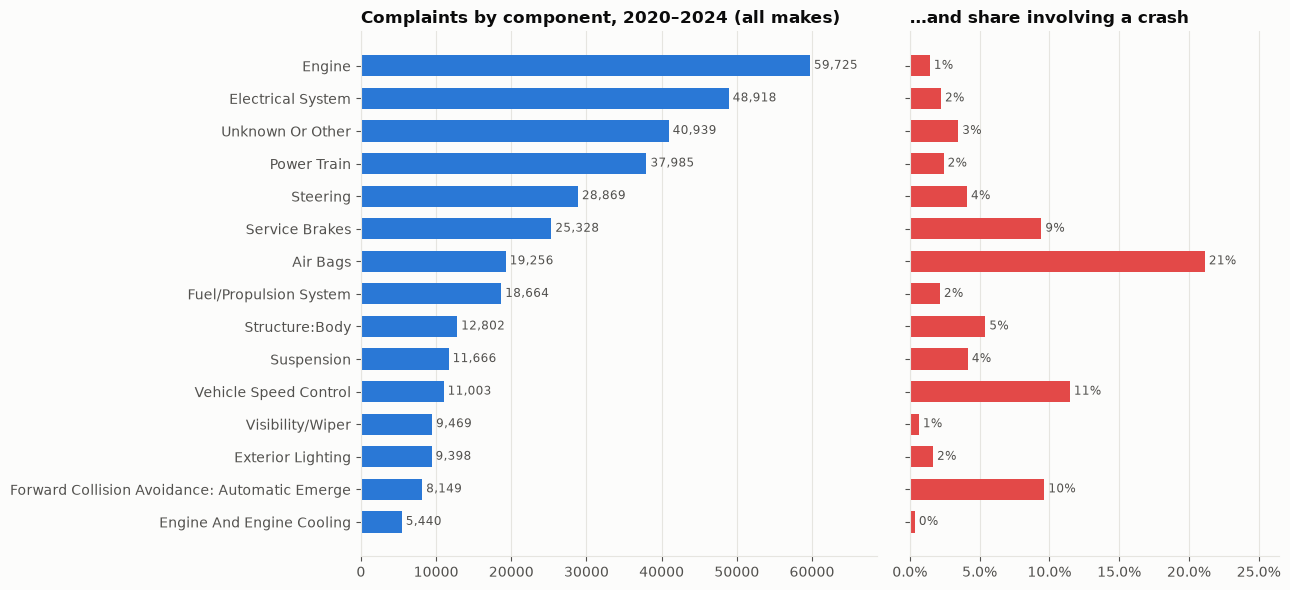

In [5]:
# Figure 1 – components: volume (blue) and crash rate (red), two separate panels sharing the same order
top = comp.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True, gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].barh(top.index.str.title().str.slice(0, 45), top["complaints"], color=BLUE, height=0.65)
for y, v in enumerate(top["complaints"]): axes[0].text(v, y, f" {v:,}", va="center", fontsize=8.5, color=INK2)
axes[0].set_title("Complaints by component, 2020–2024 (all makes)"); axes[0].grid(axis="y", visible=False)
axes[0].set_xlim(0, top["complaints"].max() * 1.15)
axes[1].barh(top.index.str.title().str.slice(0, 45), top["crash_rate"], color=RED, height=0.65)
for y, v in enumerate(top["crash_rate"]): axes[1].text(v, y, f" {v:.0%}", va="center", fontsize=8.5, color=INK2)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_title("…and share involving a crash")
axes[1].grid(axis="y", visible=False); axes[1].set_xlim(0, top["crash_rate"].max() * 1.25)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_components.png", dpi=160, bbox_inches="tight"); plt.show()

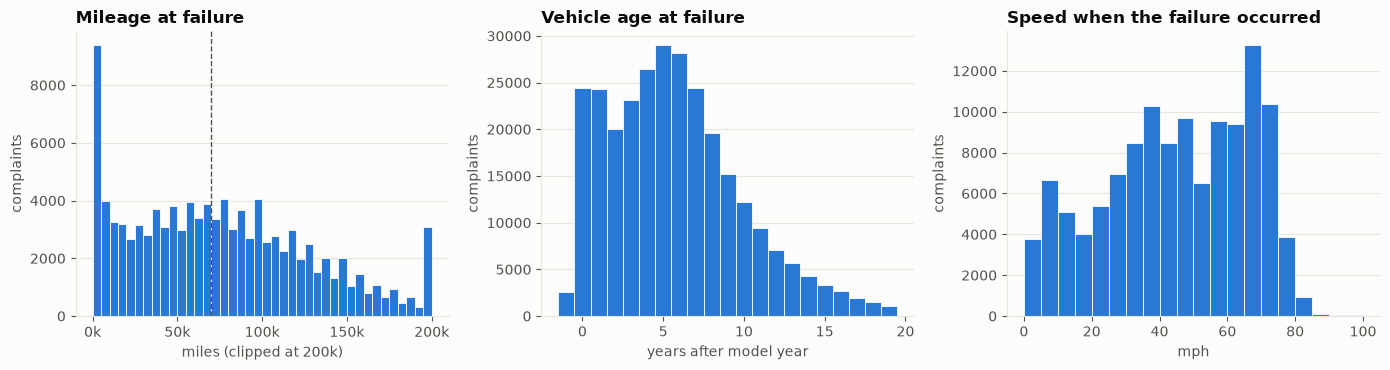

Share of complaints with failure within 3 years of model year: 24% (of those with an age: 25%)


In [6]:
# Figure 2 – distributions of the key numeric columns
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(cmp["MILES"].dropna().clip(upper=200_000), bins=40, color=BLUE, edgecolor=SURF, linewidth=0.6)
axes[0].axvline(cmp["MILES"].median(), color=INK2, ls="--", lw=1); axes[0].set_title("Mileage at failure")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k")); axes[0].set_xlabel("miles (clipped at 200k)")
axes[1].hist(cmp["vehicle_age_yrs"].dropna().clip(upper=20), bins=np.arange(-1, 21) - 0.5, color=BLUE, edgecolor=SURF, linewidth=0.6)
axes[1].set_title("Vehicle age at failure"); axes[1].set_xlabel("years after model year")
axes[2].hist(cmp["VEH_SPEED"].dropna(), bins=np.arange(0, 101, 5), color=BLUE, edgecolor=SURF, linewidth=0.6)
axes[2].set_title("Speed when the failure occurred"); axes[2].set_xlabel("mph")
for a in axes: a.grid(axis="x", visible=False); a.set_ylabel("complaints")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_distributions.png", dpi=160, bbox_inches="tight"); plt.show()
print(f"Share of complaints with failure within 3 years of model year: {(cmp['vehicle_age_yrs'] <= 2).mean():.0%} "
      f"(of those with an age: {(cmp['vehicle_age_yrs'].dropna() <= 2).mean():.0%})")

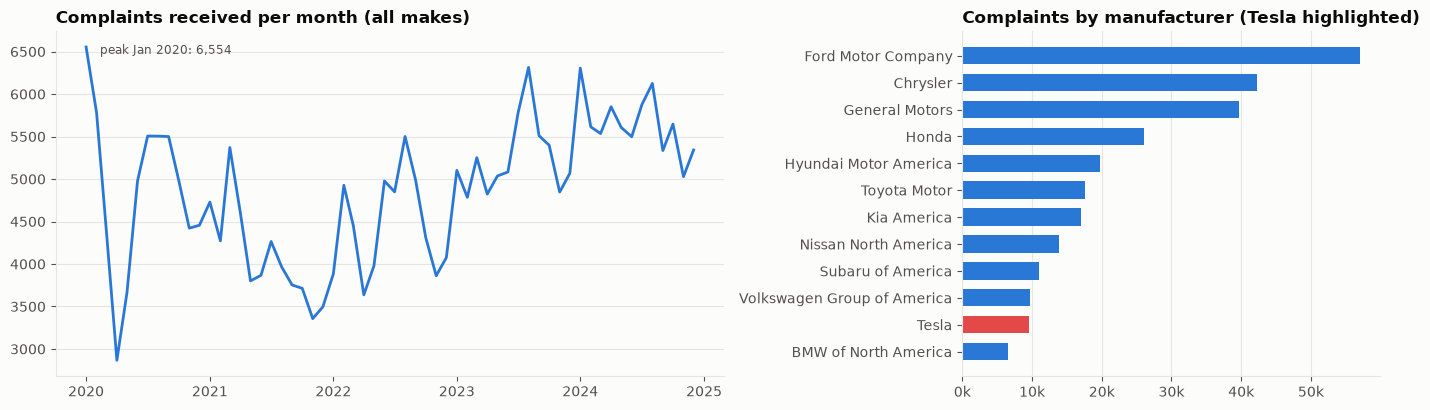

Note: raw complaint counts are not normalised by vehicles on the road, so they show where the issues are, not relative reliability.


In [7]:
# Figure 3 – monthly complaint volume and top manufacturers
monthly = cmp.groupby("recv_month").size()
mfr = cmp["MFR_NAME"].value_counts().head(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(monthly.index, monthly.values, color=BLUE, lw=2)
axes[0].set_title("Complaints received per month (all makes)"); axes[0].grid(axis="x", visible=False)
pk = monthly.idxmax(); axes[0].annotate(f"peak {pk:%b %Y}: {monthly.max():,}", (pk, monthly.max()), xytext=(10, -5),
                                        textcoords="offset points", fontsize=8.5, color=INK2)
axes[1].barh(mfr.index.str.replace(r"\s*\(.*\)|,? (Inc|LLC|Corporation|Corp|Co)\.?$", "", regex=True).str.slice(0, 28),
             mfr.values, color=[RED if FOCUS_MFR in m else BLUE for m in mfr.index], height=0.65)
axes[1].set_title(f"Complaints by manufacturer ({FOCUS_MFR} highlighted)"); axes[1].grid(axis="y", visible=False)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_trend_mfr.png", dpi=160, bbox_inches="tight"); plt.show()
print("Note: raw complaint counts are not normalised by vehicles on the road, so they show where the issues are, not relative reliability.")

## 2. Text mining: turning narratives into structured tags
### 2.1 Which columns are free text?
A column is treated as free text when values are long and almost all unique. Short, high-cardinality fields (city, dealer name)
are categorical, or PII that we dropped.

In [8]:
cand = []
for c in raw.columns:
    s = raw[c].str.strip(); s = s[s != ""]
    if len(s) == 0: continue
    cand.append({"column": c, "avg length": s.str.len().mean(), "unique ratio": s.nunique() / len(s),
                 "avg words": s.str.split().str.len().mean()})
cand = pd.DataFrame(cand).sort_values("avg length", ascending=False).head(8).reset_index(drop=True)
cand["is free text"] = (cand["avg words"] > 8) & (cand["unique ratio"] > 0.5)
cand.style.format({"avg length": "{:.0f}", "unique ratio": "{:.2f}", "avg words": "{:.1f}"})

,column,avg length,unique ratio,avg words,is free text
0,CDESCR,591,0.69,104.2,True
1,MFR_NAME,22,0.00,3.5,False
2,DEALER_NAME,20,0.46,3.2,False
3,COMPDESC,16,0.00,2.1,False
4,DOT,12,0.61,2.0,False
5,VIN,11,0.29,1.0,False
6,TIRE_SIZE,11,0.48,1.5,False
7,DEALER_TEL,10,0.59,1.0,False


`CDESCR` is the only true free-text column (about 100 words on average, more than 99% unique). `MODELTXT` and `COMPDESC` are controlled
vocabularies. `COMPDESC` is useful but coarse: one in ten complaints is `UNKNOWN OR OTHER`, and categories such as `ELECTRICAL SYSTEM`
say nothing about the symptom. The narrative holds the symptom, the trigger and the consequence.

### 2.2 Build the focus corpus (one row per complaint)

In [9]:
foc = df[df["MFR_NAME"].str.contains(FOCUS_MFR, case=False, na=False) & df["CDESCR"].ne("")]
# collapse complaint x component rows -> one row per complaint, keeping every NHTSA component it was filed under
corpus = (foc.sort_values("COMPDESC").groupby("ODINO")
          .agg(**{c: (c, "first") for c in ["MODELTXT", "YEARTXT", "LDATE", "FAILDATE", "recv_month", "CRASH", "FIRE", "INJURED", "DEATHS",
                                            "MILES", "VEH_SPEED", "STATE", "MEDICAL_ATTN", "VEHICLES_TOWED_YN", "CDESCR", "severe", "vehicle_age_yrs"]},
               nhtsa_components=("COMPDESC", lambda s: "; ".join(sorted(set(s)))))
          .reset_index())

# Text that describes *how the complaint was filed*, not the failure. Left in, it makes clusters group by writing style.
BOILERPLATE = [
    r"information redacted pursuant to the freedom of information act \(foia\),? 5 u\.?s\.?c\.? 552\(b\)\(6\)\.?",
    r"https?://\S+|www\.\S+",                                               # links to photos / videos
    r"\[(your|my) [^\]]{2,30}\]",                                           # template placeholders, e.g. [Your Phone Number]
    # NHTSA hotline (staff-written) template: keep the failure description, drop the frame around it
    r"the contact owns an? \d{4} [\w\- ]{2,40}?\.",
    r"the contact stated( that)?",
    r"the (local )?dealer( \(.{0,40}?\))? was (not )?(contacted|notified)[^.]*\.",
    r"the manufacturer was (not )?(notified|made aware)[^.]*\.",
    r"the vehicle was (not )?(diagnosed|repaired|taken)[^.]*\.",
    r"the (approximate )?failure mileage was (approximately |about )?[\d,\.]+( miles)?\.?",
    r"(the )?vin was (not )?(available|unknown|included)[^.]*\.",
]
BOILER_RX = re.compile("|".join(BOILERPLATE), re.I)

def clean_text(t):
    t = t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    t = BOILER_RX.sub(" ", t)
    t = re.sub(r"\bX{2,}\b|\[XXX\]|\*+", " ", t)              # NHTSA redaction markers (XXX) for personal info
    t = re.sub(r"\s+", " ", t).strip()
    return t

corpus["is_hotline_template"] = corpus["CDESCR"].str.contains(r"the contact owns", case=False)

corpus["text"]  = corpus["CDESCR"].map(clean_text)
corpus["lower"] = corpus["text"].str.lower()
corpus["MODELTXT"] = corpus["MODELTXT"].str.title()
print(f"{FOCUS_MFR} corpus: {len(corpus):,} complaints | models: " + ", ".join(f"{k} {v:,}" for k, v in corpus['MODELTXT'].value_counts().head(5).items()))
print(f"Upper-case-only narratives (older submission channels): {(corpus['text'] == corpus['text'].str.upper()).mean():.0%} -> handled by lower-casing")

Tesla corpus: 9,544 complaints | models: Model 3 3,291, Model Y 2,805, Model S 2,343, Model X 1,053, Cybertruck 27
Upper-case-only narratives (older submission channels): 18% -> handled by lower-casing


### 2.3 Entity and tag extraction
The brief's own entity examples were in the missing Excel file, so we defined an entity schema suited to failure analysis.
Each class is extracted with a curated pattern dictionary (transparent, auditable, fast on hundreds of thousands of narratives).
Numeric entities are pulled out with regular expressions:

| Entity class | Examples of extracted tags |
|---|---|
| **COMPONENT** | suspension control arm, 12V battery, touchscreen/MCU, camera, windshield, door handle, seat belt, HV battery |
| **FAILURE_MODE / SYMPTOM** | phantom braking, loss of power, steering lock-up, screen blackout, noise/clunk, warning message, leak, overheating |
| **ADAS_FEATURE** | Autopilot, FSD, traffic-aware cruise, AEB, forward collision warning, lane keep/departure |
| **TRIGGER / CONDITION** | overpass/bridge shadow, oncoming vehicle, highway, rain/snow, night/sun glare, after software update |
| **CONSEQUENCE** | crash, near-miss / rear-end risk, injury, towed, stranded |
| **SERVICE_ACTION** | service centre visit, part replaced, could not reproduce, warranty denied, recall, out-of-pocket cost |
| **NUMERIC** | speed (mph), mileage, repair cost ($) |

In [10]:
ENTITY_PATTERNS = {
 "COMPONENT": {
   "Suspension / control arm": r"control arm|ball joint|suspension|strut|knuckle|tie rod|toe link|lower arm|upper arm",
   "Steering":                 r"steering (wheel|rack|column)|power steering|steering assist|\beps\b|steering",
   "Brakes (hardware)":        r"brake pad|rotor|caliper|brake pedal|brake fluid|parking brake|regen(erative)? brak",
   "Touchscreen / MCU":        r"touch ?screen|\bscreen\b|display|\bmcu\b|infotainment|center console screen|emmc",
   "12V battery / low-voltage":r"12 ?v(olt)?\b|low voltage battery|12-volt",
   "HV battery / drive unit":  r"high voltage battery|hv battery|battery pack|drive unit|inverter|motor|traction battery|range",
   "Charging system":          r"charg(e|ing) port|charger|supercharg|charging|j1772|wall connector",
   "Camera / sensors":         r"camera|sensor|radar|ultrasonic|\bvision\b",
   "Windshield / glass":       r"windshield|windscreen|glass|roof",
   "Door / handle / windows":  r"door handle|door|window|falcon wing",
   "Seat belt / airbag":       r"seat ?belt|airbag|air bag|srs",
   "Seats":                    r"\bseat\b|seats",
   "Lights":                   r"headlight|head light|tail ?light|high beam|auto ?high ?beam|lights?\b",
   "Wipers":                   r"wiper",
   "HVAC / heat pump":         r"heat pump|\bhvac\b|air condition|\ba/?c\b|defrost|heater|climate",
   "Tires / wheels":           r"\btires?\b|\btyres?\b|wheel|rim\b|lug nut",
   "Trunk / frunk / tailgate": r"trunk|frunk|liftgate|tailgate|hatch",
   "Accelerator / pedal":      r"accelerator|gas pedal|go pedal|pedal",
   "Horn / yoke controls":     r"\bhorn\b|\byoke\b|steering wheel button|scroll wheel",
 },
 "FAILURE_MODE": {
   "Phantom / false braking":       r"phantom bre?ak|bre?ak(ed|es|ing|s) (hard |suddenly |abruptly |violently )?for no (apparent )?reason|"
                                    r"(sudden|unexpected|unintended|random|abrupt|hard) (and \w+ )?bre?ak|slam(med|s)? (on )?the bre?aks|false (positive|alarm|alert)|"
                                    r"bre?aked (hard|suddenly)|ghost bre?ak",
   "Failure to brake / detect":     r"did not (brake|stop|slow|detect|see)|didn't (brake|stop|slow|detect|see)|failed to (brake|stop|slow|detect)|no warning|"
                                    r"did not warn|didn't warn",
   "Unintended acceleration":       r"unintended acceleration|sudden(ly)? accelerat|accelerated (on its own|by itself|suddenly)|surge|lurch",
   "Loss of power / shutdown":      r"loss of (motive )?power|lost (all )?power|shut (down|off)|died|dead|power(ed)? off|won't start|will not start|"
                                    r"would not start|not start|reduced power|limp mode|stalled",
   "Steering failure / pull":       r"steering (lock|fail|went out|assist reduced|stopped)|lost steering|loss of steering|pull(s|ed|ing)? to the (left|right)|"
                                    r"jerk(ed|s)? the (steering )?wheel|wheel (jerk|yank)",
   "Screen blackout / reboot":      r"screen (went |goes |turned )?(black|blank|dark|frozen|freez)|black screen|blank screen|reboot|"
                                    r"(screen|display) (froze|freez|unresponsive|crash)|yellow (border|edge)",
   "Broke / snapped / separated":   r"\bbroke\b|broken|snapp|separat|detach|came off|fell off|crack(ed)?\b|fractur|collaps",
   "Noise / clunk / vibration":     r"noise|clunk|knock|rattl|squeak|vibrat|grind|creak|pop(ping)? sound|shak",
   "Warning message / alert":       r"warning (message|light|alert)|error (message|code)|alert(s)?\b|chime|beep|message (said|stating)",
   "Leak (water/fluid)":            r"\bleak|water (intrusion|ingress|in the)|coolant|flood",
   "Overheating / smoke / burning": r"overheat|smoke|burning|melt|thermal|caught fire|\bfire\b|flames",
   "Not charging / range loss":     r"(won't|will not|wouldn't|stopped|not) charg|range (loss|drop|decreas|reduc)|degradat|lost (\d+ )?miles of range",
   "Door / handle malfunction":     r"(door|handle)s? (would not|won't|wouldn't|did not|didn't|fail(ed)? to|stopped) (open|present|extend|work|close)|trapped|locked (in|out)",
   "Wipers / lights malfunction":   r"wipers? (turn(ed)? on|go(es)? on|activat|randomly|not working|didn't|did not|fail)|auto ?high ?beams? (fail|not|don't|didn't|flash)",
   "Seat belt / airbag fault":      r"airbag (light|warning|fault|did not|didn't|fail)|seat ?belt (fail|did not|didn't|won't|retract|lock)",
 },
 "ADAS_FEATURE": {
   "Autopilot":                   r"autopilot|auto pilot|auto-pilot",
   "Full Self-Driving (FSD)":     r"\bfsd\b|full self[- ]driving|self[- ]driving",
   "Traffic-aware / adaptive cruise": r"cruise control|tacc|traffic aware|adaptive cruise",
   "Automatic emergency braking": r"\baeb\b|automatic emergency brak|emergency brak|collision avoidance",
   "Forward collision warning":   r"forward collision|\bfcw\b|collision warning",
   "Lane keep / departure":       r"lane (keep|depart|assist)|autosteer|auto steer|lane change|blind spot",
 },
 "TRIGGER_CONDITION": {
   "Highway / freeway":            r"highway|freeway|interstate|motorway|expressway",
   "Overpass / bridge / shadow":   r"overpass|bridge|underpass|shadow|tunnel",
   "Oncoming / passing vehicle":   r"oncoming|opposite lane|on-coming|passing (truck|car|vehicle)|semi[- ]truck|truck (passing|approach)",
   "Weather (rain/snow/fog)":      r"\brain\b|raining|snow|fog|\bice\b|icy|wet road",
   "Low light / glare":            r"\bnight\b|dark|sun ?glare|sunlight|sun was|low sun",
   "After software update":        r"(software|firmware|ota|over the air) update|after (the |an )?update|update[d]? (to )?(version|v?\d{4}\.\d+)|\bversion \d{4}",
   "Low speed / parking":          r"parking lot|park(ed|ing)\b|garage|driveway|low speed|reversing|backing (up|out)",
   "Cold temperature":             r"cold (weather|temperature|morning)|freezing|below zero|winter",
 },
 "CONSEQUENCE": {
   "Crash / collision":       r"\bcrash|collision|collided|hit (a|the|another)|rear[- ]ended|struck|accident|totaled|totalled",
   "Near-miss":               r"near(ly)? (miss|caus|hit|rear)|almost (hit|caus|rear|crash)|close call|narrowly",
   "Injury":                  r"injur|hospital|whiplash|\bhurt\b|bruis|concussion|emergency room",
   "Towed / stranded":        r"\btow(ed|ing)?\b|stranded|flatbed|roadside assistance",
 },
 "SERVICE_ACTION": {
   "Service centre visit":    r"service (center|centre|appointment|visit|tech|department)|took (it|the car) (in|to)|mobile service|dealer",
   "Part replaced / repaired":r"replac(ed|ing|ement)|repair(ed)?|fixed",
   "Could not reproduce":     r"could not (reproduce|replicate|find|duplicate)|couldn't (reproduce|replicate|find)|no (problem|issue|fault) found|"
                              r"unable to (reproduce|replicate|duplicate)|operating as designed|working as (designed|intended)|normal behavior",
   "Warranty denied / cost":  r"not covered|denied|refused|out of (my )?pocket|\$\s?\d|charged me|wouldn't cover|would not cover",
   "Recall referenced":       r"\brecall",
 },
}
COMPILED = {cls: {tag: re.compile(p) for tag, p in d.items()} for cls, d in ENTITY_PATTERNS.items()}

def extract_entities(text):
    return {cls: [tag for tag, rx in d.items() if rx.search(text)] for cls, d in COMPILED.items()}

ents = corpus["lower"].map(extract_entities)
for cls in ENTITY_PATTERNS:
    corpus[cls] = ents.map(lambda e: e[cls])

# Numeric entities
def first_num(rx, text, lo, hi):
    vals = [float(v.replace(",", "")) for v in re.findall(rx, text)]
    vals = [v for v in vals if lo <= v <= hi]
    return vals[0] if vals else np.nan
corpus["speed_mph_text"] = corpus["lower"].map(lambda t: first_num(r"(\d{1,3})\s?(?:mph|miles per hour|m\.p\.h)", t, 1, 130))
corpus["mileage_text"]   = corpus["lower"].map(lambda t: first_num(r"(\d{1,3}(?:,\d{3})+|\d{3,6})\s?(?:miles|mi\b)", t, 10, 400000))
corpus["cost_usd_text"]  = corpus["lower"].map(lambda t: first_num(r"\$\s?(\d{1,3}(?:,\d{3})+|\d+)", t, 20, 60000))
corpus["speed_mph"] = corpus["VEH_SPEED"].fillna(corpus["speed_mph_text"])         # structured value first, text as fallback

ENT_CLASSES = list(ENTITY_PATTERNS)
corpus["n_tags"] = corpus[ENT_CLASSES].apply(lambda r: sum(len(x) for x in r), axis=1)
print(f"Complaints with ≥1 tag: {(corpus['n_tags'] > 0).mean():.1%} | avg tags per complaint: {corpus['n_tags'].mean():.1f}")
print(f"Speed recovered from text where structured speed was missing: {(corpus['VEH_SPEED'].isna() & corpus['speed_mph_text'].notna()).sum():,} complaints")
tag_freq = (pd.concat([corpus[c].explode().dropna().rename("tag").to_frame().assign(entity_class=c) for c in ENT_CLASSES])
            .value_counts().rename("complaints").reset_index())
tag_freq["% of complaints"] = tag_freq["complaints"] / len(corpus)
tag_freq.groupby("entity_class").head(5).style.format({"% of complaints": "{:.1%}"})

Complaints with ≥1 tag: 98.2% | avg tags per complaint: 4.4
Speed recovered from text where structured speed was missing: 178 complaints


,tag,entity_class,complaints,% of complaints
0,Crash / collision,CONSEQUENCE,2953,30.9%
1,Highway / freeway,TRIGGER_CONDITION,2377,24.9%
2,Part replaced / repaired,SERVICE_ACTION,2155,22.6%
3,Traffic-aware / adaptive cruise,ADAS_FEATURE,1951,20.4%
4,Touchscreen / MCU,COMPONENT,1916,20.1%
5,Phantom / false braking,FAILURE_MODE,1723,18.1%
6,Service centre visit,SERVICE_ACTION,1655,17.3%
7,Tires / wheels,COMPONENT,1644,17.2%
8,Autopilot,ADAS_FEATURE,1614,16.9%
9,Low speed / parking,TRIGGER_CONDITION,1381,14.5%


In [11]:
# Data-driven key phrases (complement to the dictionary): top TF-IDF 2–3-grams per complaint
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
STOP = list(ENGLISH_STOP_WORDS | {"tesla", "model", "car", "vehicle", "drive", "driving", "just", "like", "time", "times", "did", "got", "said",
                                  "told", "day", "went", "way", "going", "know", "really", "happened", "happen", "happens", "issue", "problem", "contact", "stated"})
tfidf = TfidfVectorizer(ngram_range=(2, 3), stop_words=STOP, min_df=8, max_df=0.3, sublinear_tf=True,
                        token_pattern=r"(?u)\b[a-z][a-z]+\b")
Xt = tfidf.fit_transform(corpus["lower"])
vocab = np.array(tfidf.get_feature_names_out())
def top_phrases(i, k=3):
    row = Xt.getrow(i); idx = row.indices[np.argsort(row.data)[::-1][:k]]
    return list(vocab[idx])
corpus["key_phrases"] = [top_phrases(i) for i in range(Xt.shape[0])]

# Spot-check: random complaints with their extracted tags (manual precision check)
for _, r in corpus.sample(4, random_state=11).iterrows():
    print("─" * 110); print(r["text"][:420], "…")
    for c in ENT_CLASSES:
        if r[c]: print(f"   {c:<18} {r[c]}")
    print(f"   {'KEY_PHRASES':<18} {r['key_phrases']}  | speed={r['speed_mph']}  miles={r['MILES'] if pd.notna(r['MILES']) else r['mileage_text']}")

──────────────────────────────────────────────────────────────────────────────────────────────────────────────
while parked in a parking lot, the contact depressed the brake pedal and was not sure if she had placed the vehicle into reverse, the vehicle accelerated backward and hit the back wall across from her parked vehicle. The vehicle trunk lid and the bumper were damaged and crumpled. no warning light was illuminated. The contact had not taken the vehicle to a local dealer but was advised by the manufacturer to take the v …
   COMPONENT          ['Brakes (hardware)', 'Lights', 'Trunk / frunk / tailgate', 'Accelerator / pedal']
   FAILURE_MODE       ['Failure to brake / detect', 'Unintended acceleration', 'Warning message / alert']
   TRIGGER_CONDITION  ['Low speed / parking']
   CONSEQUENCE        ['Crash / collision']
   SERVICE_ACTION     ['Service centre visit', 'Part replaced / repaired']
   KEY_PHRASES        ['parked parking lot', 'hit wall', 'taken local dealer']  | speed=na

### 2.4 Categorise "type of issue"
Mined tags plus NHTSA's component code are grouped into **issue types** a quality team would own. The rules are applied in order,
and a complaint can have several issue types. The **primary issue** is the first match, ordered from most specific to most generic.

In [12]:
def has(r, cls, *tags):  return any(t in r[cls] for t in tags)
def nhtsa(r, *kw):       return any(k in r["nhtsa_components"] for k in kw)

ISSUE_RULES = [
 ("ADAS false activation (phantom braking)", lambda r: has(r, "FAILURE_MODE", "Phantom / false braking") or
        (nhtsa(r, "AUTOMATIC EMERGENCY BRAKING", "FORWARD COLLISION AVOIDANCE") and has(r, "TRIGGER_CONDITION", "Overpass / bridge / shadow", "Oncoming / passing vehicle"))),
 ("ADAS failure to act / steer",           lambda r: has(r, "FAILURE_MODE", "Failure to brake / detect") and (r["ADAS_FEATURE"] or nhtsa(r, "FORWARD COLLISION", "LANE DEPARTURE"))
        or (has(r, "ADAS_FEATURE", "Lane keep / departure", "Autopilot", "Full Self-Driving (FSD)") and has(r, "CONSEQUENCE", "Crash / collision", "Near-miss"))),
 ("Unintended acceleration",               lambda r: has(r, "FAILURE_MODE", "Unintended acceleration")),
 ("Suspension / steering component failure", lambda r: has(r, "COMPONENT", "Suspension / control arm") and has(r, "FAILURE_MODE", "Broke / snapped / separated", "Noise / clunk / vibration", "Steering failure / pull")
        or nhtsa(r, "SUSPENSION") or (nhtsa(r, "STEERING") and has(r, "FAILURE_MODE", "Steering failure / pull", "Broke / snapped / separated", "Noise / clunk / vibration"))),
 ("Loss of power / drive unit / HV battery", lambda r: has(r, "FAILURE_MODE", "Loss of power / shutdown") and not has(r, "COMPONENT", "Touchscreen / MCU")
        or nhtsa(r, "POWER TRAIN", "ELECTRIC PROPULSION")),
 ("Fire / thermal event",                 lambda r: bool(r["FIRE"]) or has(r, "FAILURE_MODE", "Overheating / smoke / burning")),
 ("Electrical / electronics & software",  lambda r: has(r, "FAILURE_MODE", "Screen blackout / reboot", "Warning message / alert") or has(r, "COMPONENT", "Touchscreen / MCU", "12V battery / low-voltage", "Camera / sensors", "Horn / yoke controls")
        or nhtsa(r, "ELECTRICAL")),
 ("Charging / range",                      lambda r: has(r, "FAILURE_MODE", "Not charging / range loss") or has(r, "COMPONENT", "Charging system")),
 ("Brakes (hardware / pedal)",             lambda r: nhtsa(r, "SERVICE BRAKES") and not has(r, "FAILURE_MODE", "Phantom / false braking") or has(r, "COMPONENT", "Brakes (hardware)")),
 ("Body, glass, doors & leaks",            lambda r: has(r, "FAILURE_MODE", "Leak (water/fluid)", "Door / handle malfunction") or nhtsa(r, "STRUCTURE", "LATCHES")
        or has(r, "COMPONENT", "Windshield / glass", "Door / handle / windows", "Trunk / frunk / tailgate") and has(r, "FAILURE_MODE", "Broke / snapped / separated")),
 ("Visibility: wipers & lights",           lambda r: has(r, "FAILURE_MODE", "Wipers / lights malfunction") or nhtsa(r, "VISIBILITY", "EXTERIOR LIGHTING")),
 ("Restraints: seat belts, airbags, seats", lambda r: has(r, "FAILURE_MODE", "Seat belt / airbag fault") or nhtsa(r, "AIR BAGS", "SEAT BELTS", "SEATS")),
 ("Tires & wheels",                        lambda r: nhtsa(r, "TIRES", "WHEELS") or has(r, "COMPONENT", "Tires / wheels") and has(r, "FAILURE_MODE", "Broke / snapped / separated")),
 ("HVAC / climate",                        lambda r: has(r, "COMPONENT", "HVAC / heat pump") and bool(r["FAILURE_MODE"])),
 ("Driver-assistance: other",              lambda r: bool(r["ADAS_FEATURE"]) or nhtsa(r, "FORWARD COLLISION", "LANE DEPARTURE", "VEHICLE SPEED CONTROL", "BACK OVER")),
]
ISSUE_GROUP = {   # higher-level "type of issue" buckets, as in the brief's examples
 "ADAS false activation (phantom braking)": "Software / ADAS behaviour", "ADAS failure to act / steer": "Software / ADAS behaviour",
 "Driver-assistance: other": "Software / ADAS behaviour", "Unintended acceleration": "Software / ADAS behaviour",
 "Suspension / steering component failure": "Mechanical component failure", "Brakes (hardware / pedal)": "Mechanical component failure",
 "Tires & wheels": "Mechanical component failure", "Body, glass, doors & leaks": "Body & structural",
 "Electrical / electronics & software": "Electrical / electronic issue", "Visibility: wipers & lights": "Electrical / electronic issue",
 "Loss of power / drive unit / HV battery": "Powertrain & HV battery", "Charging / range": "Powertrain & HV battery",
 "Fire / thermal event": "Fire / thermal", "Restraints: seat belts, airbags, seats": "Occupant protection", "HVAC / climate": "Comfort / HVAC",
}

def classify(r):
    hits = [name for name, rule in ISSUE_RULES if rule(r)]
    return hits or ["Unclassified"]
corpus["issue_types"]   = corpus.apply(classify, axis=1)
corpus["primary_issue"] = corpus["issue_types"].str[0]
corpus["issue_group"]   = corpus["primary_issue"].map(ISSUE_GROUP).fillna("Unclassified")

issue_summary = (corpus.groupby("primary_issue")
                 .agg(complaints=("ODINO", "size"), crash_rate=("CRASH", "mean"), injury_rate=("INJURED", lambda s: (s.fillna(0) > 0).mean()),
                      fire_rate=("FIRE", "mean"), median_speed=("speed_mph", "median"), median_miles=("MILES", "median"),
                      median_age_yrs=("vehicle_age_yrs", "median"))
                 .sort_values("complaints", ascending=False))
issue_summary["share"] = issue_summary["complaints"] / len(corpus)
issue_summary.insert(0, "issue_group", issue_summary.index.map(ISSUE_GROUP).fillna("Unclassified"))
print(f"Classified: {(corpus['primary_issue'] != 'Unclassified').mean():.1%} of complaints")
issue_summary.style.format({"crash_rate": "{:.1%}", "injury_rate": "{:.1%}", "fire_rate": "{:.1%}", "median_speed": "{:.0f}",
                            "median_miles": "{:,.0f}", "median_age_yrs": "{:.1f}", "share": "{:.1%}"})

Classified: 96.1% of complaints


,issue_group,complaints,crash_rate,injury_rate,fire_rate,median_speed,median_miles,median_age_yrs,share
primary_issue,,,,,,,,,
Electrical / electronics & software,Electrical / electronic issue,2766,4.4%,1.8%,0.0%,45,"50,000",3.0,29.0%
ADAS false activation (phantom braking),Software / ADAS behaviour,1992,1.9%,0.8%,0.1%,70,"6,900",1.0,20.9%
Suspension / steering component failure,Mechanical component failure,1035,5.9%,1.4%,1.0%,25,"34,000",4.0,10.8%
ADAS failure to act / steer,Software / ADAS behaviour,753,27.2%,8.0%,0.5%,65,"18,000",1.0,7.9%
Driver-assistance: other,Software / ADAS behaviour,718,8.6%,3.6%,0.0%,65,"5,000",1.0,7.5%
Loss of power / drive unit / HV battery,Powertrain & HV battery,425,8.0%,2.1%,2.4%,45,"35,117",2.0,4.5%
Unclassified,Unclassified,376,6.9%,2.9%,0.0%,35,"41,000",2.0,3.9%
Brakes (hardware / pedal),Mechanical component failure,326,14.4%,3.7%,0.0%,65,"10,222",1.0,3.4%
"Body, glass, doors & leaks",Body & structural,264,6.4%,5.3%,0.0%,45,"30,000",2.0,2.8%


In [13]:
# How much does text mining add over NHTSA's own component code?
unk = corpus["nhtsa_components"].eq("UNKNOWN OR OTHER")
print(f"Complaints filed only as 'UNKNOWN OR OTHER': {unk.sum():,} ({unk.mean():.1%}); "
      f"text mining assigns an issue type to {(corpus.loc[unk, 'primary_issue'] != 'Unclassified').mean():.0%} of them")
print(corpus.loc[unk, "primary_issue"].value_counts().head(6).to_string())

Complaints filed only as 'UNKNOWN OR OTHER': 870 (9.1%); text mining assigns an issue type to 74% of them
primary_issue
Electrical / electronics & software        460
Unclassified                               228
ADAS failure to act / steer                 36
Body, glass, doors & leaks                  29
Loss of power / drive unit / HV battery     27
Unintended acceleration                     24


## 3. Clustering and topic modelling: grouping failure modes without rules
The rule-based issue types encode what we already expect. To find groups we *didn't* anticipate and to check the rules, we cluster
the narratives on meaning:
1. **Sentence embeddings** (`all-MiniLM-L6-v2`) turn each complaint into a 384-dimensional vector, so similar complaints sit close together
   even with different wording.
2. **K-Means** groups the vectors. *k* is chosen by silhouette score.
3. Each cluster is labelled by its most distinctive terms (**class-based TF-IDF**, as in BERTopic) and its dominant tags.
4. **NMF topic modelling** on TF-IDF runs as an independent second method to confirm the main themes.

In [14]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

emb_path = OUT_DIR / f"embeddings_{FOCUS_MFR.lower()}.npy"
if emb_path.exists() and len(np.load(emb_path)) == len(corpus):
    E = np.load(emb_path)                                            # cache: embeddings take a few minutes on CPU
else:
    model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    E = model.encode(corpus["text"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    np.save(emb_path, E)

rng = np.random.RandomState(42); sample = rng.choice(len(E), size=min(4000, len(E)), replace=False)
sil = {k: silhouette_score(E[sample], KMeans(k, n_init=5, random_state=42).fit_predict(E[sample])) for k in range(6, 19, 2)}
K = max(sil, key=sil.get)
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "-> k =", K)
km = KMeans(K, n_init=10, random_state=42).fit(E)
corpus["cluster"] = km.labels_

# class-based TF-IDF: concatenate each cluster's docs, score unigrams+bigrams per cluster
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(ngram_range=(1, 2), stop_words=STOP, min_df=5, token_pattern=r"(?u)\b[a-z][a-z]+\b")
docs = corpus.groupby("cluster")["lower"].apply(" ".join)
C = cv.fit_transform(docs).toarray().astype(float)
tf = C / C.sum(axis=1, keepdims=True); idf = np.log(1 + C.sum() / C.sum(axis=0))
ctfidf = tf * idf; terms = np.array(cv.get_feature_names_out())
cluster_terms = {c: ", ".join(terms[np.argsort(ctfidf[i])[::-1][:8]]) for i, c in enumerate(docs.index)}

def top_share(s, n=2):
    vc = s.explode().dropna().value_counts(normalize=False) / len(s)
    return "; ".join(f"{k} ({v:.0%})" for k, v in vc.head(n).items())
clusters = corpus.groupby("cluster").agg(
    complaints=("ODINO", "size"), top_terms=("cluster", lambda s: cluster_terms[s.iloc[0]]),
    dominant_issue=("primary_issue", lambda s: s.value_counts().index[0]),
    issue_purity=("primary_issue", lambda s: s.value_counts(normalize=True).iloc[0]),
    top_failure_modes=("FAILURE_MODE", top_share), top_triggers=("TRIGGER_CONDITION", top_share),
    crash_rate=("CRASH", "mean"), median_speed=("speed_mph", "median"), median_miles=("MILES", "median"),
    top_model=("MODELTXT", lambda s: f"{s.value_counts().index[0]} ({s.value_counts(normalize=True).iloc[0]:.0%})"),
).sort_values("complaints", ascending=False)
clusters.style.format({"issue_purity": "{:.0%}", "crash_rate": "{:.1%}", "median_speed": "{:.0f}", "median_miles": "{:,.0f}"})

Silhouette by k: {6: 0.048, 8: 0.042, 10: 0.048, 12: 0.053, 14: 0.051, 16: 0.056, 18: 0.052} -> k = 16


,complaints,top_terms,dominant_issue,issue_purity,top_failure_modes,top_triggers,crash_rate,median_speed,median_miles,top_model
cluster,,,,,,,,,,
9,1010,"cruise, cruise control, control, brakes, lane, braking, highway, speed",ADAS false activation (phantom braking),38%,Phantom / false braking (26%); Failure to brake / detect (11%),Highway / freeway (57%); Oncoming / passing vehicle (11%),1.1%,70,"5,000",Model 3 (48%)
4,889,"lane, speed, stop, right, incident, warning, brake, road",ADAS failure to act / steer,21%,Failure to brake / detect (19%); Warning message / alert (17%),Highway / freeway (34%); Low speed / parking (31%),40.6%,45,"11,607",Model Y (38%)
11,857,"braking, cruise, control, cruise control, phantom, phantom braking, brakes, autopilot",ADAS false activation (phantom braking),76%,Phantom / false braking (70%); Failure to brake / detect (12%),Highway / freeway (57%); Oncoming / passing vehicle (12%),1.8%,70,"10,300",Model Y (47%)
3,804,"parking, warning, mph, stop, left, wheel, right, brake",ADAS failure to act / steer,14%,Failure to brake / detect (20%); Warning message / alert (18%),Low speed / parking (33%); Highway / freeway (17%),35.1%,35,"16,035",Model Y (36%)
2,785,"suspension, wheel, tire, service, noise, control, arm, tires",Suspension / steering component failure,82%,Noise / clunk / vibration (41%); Broke / snapped / separated (39%),Low speed / parking (24%); Highway / freeway (13%),4.2%,30,"25,000",Model S (37%)
6,717,"phantom, braking, phantom braking, cruise, cruise control, control, highway, autopilot",ADAS false activation (phantom braking),98%,Phantom / false braking (98%); Failure to brake / detect (11%),Highway / freeway (47%); Overpass / bridge / shadow (11%),0.3%,70,"4,750",Model 3 (47%)
7,713,"service, recall, battery, safety, warranty, charge, center, repair",Electrical / electronics & software,36%,Loss of power / shutdown (14%); Warning message / alert (10%),Low speed / parking (13%); After software update (12%),3.8%,50,"42,500",Model 3 (32%)
12,698,"screen, mcu, failure, turn, control, camera, display, working",Electrical / electronics & software,75%,Screen blackout / reboot (21%); Loss of power / shutdown (8%),Low speed / parking (9%); Weather (rain/snow/fog) (6%),0.7%,45,"59,400",Model S (61%)
0,672,"turn, lane, safety, driver, wipers, update, autopilot, software",Electrical / electronics & software,35%,Warning message / alert (11%); Loss of power / shutdown (5%),Highway / freeway (20%); After software update (18%),1.9%,53,"20,454",Model 3 (45%)


In [15]:
# Independent check: NMF topic model on TF-IDF unigrams+bigrams
from sklearn.decomposition import NMF
tf_uni = TfidfVectorizer(ngram_range=(1, 2), stop_words=STOP, min_df=10, max_df=0.4, token_pattern=r"(?u)\b[a-z][a-z]+\b")
Xu = tf_uni.fit_transform(corpus["lower"])
nmf = NMF(n_components=K, random_state=42, init="nndsvda", max_iter=400).fit(Xu)
W = nmf.transform(Xu); corpus["nmf_topic"] = W.argmax(axis=1)
vu = np.array(tf_uni.get_feature_names_out())
nmf_topics = pd.DataFrame({"topic": range(K), "top_terms": [", ".join(vu[np.argsort(c)[::-1][:8]]) for c in nmf.components_],
                           "complaints": np.bincount(corpus["nmf_topic"], minlength=K)}).sort_values("complaints", ascending=False)
from sklearn.metrics import adjusted_mutual_info_score
print(f"Agreement between embedding clusters and NMF topics (adjusted mutual information): "
      f"{adjusted_mutual_info_score(corpus['cluster'], corpus['nmf_topic']):.2f} (0 = random, 1 = identical)")
nmf_topics

Agreement between embedding clusters and NMF topics (adjusted mutual information): 0.44 (0 = random, 1 = identical)


,topic,top_terms,complaints
15,15,"service, service center, center, safety, software, update, recall, battery",1419
7,7,"cruise, cruise control, control, adaptive, adaptive cruise, using, using cruise, brakes",956
12,12,"parking, brake, accelerated, stop, pedal, acceleration, hit, lot",913
8,8,"suspension, tire, wheel, arm, control arm, noise, tires, link",890
1,1,"screen, mcu, camera, controls, unit, black, main, display",748
6,6,"braking, phantom braking, phantom, experienced, experienced phantom, emergency braking...",729
0,0,"lane, autopilot, highway, brakes, speed, road, mph, traffic",722
2,2,"steering, power, power steering, wheel, steering wheel, assist, steering assist, reduced",490
11,11,"turn, signal, turn signal, left, signals, turn signals, buttons, right",465
5,5,"seat, passenger, restraint, fault, safety restraint, safety, restraint fault, passenge...",407


### 3.1 Root-cause profiling of recurring failures
For each major issue, we compare how often each **trigger/condition** tag appears in that issue versus all other complaints (the **lift**).
We add mileage, model year and model concentration. A high lift means the condition is characteristic of the failure, which makes it a
root-cause hypothesis to verify with engineering data.

In [16]:
def lift_table(mask, cls="TRIGGER_CONDITION", min_n=15):
    inside = corpus.loc[mask, cls].explode().value_counts() / mask.sum()
    outside = corpus.loc[~mask, cls].explode().value_counts() / (~mask).sum()
    t = pd.DataFrame({"share_in_issue": inside, "share_elsewhere": outside}).fillna(0)
    t["lift"] = t["share_in_issue"] / t["share_elsewhere"].replace(0, np.nan)
    t = t[corpus.loc[mask, cls].explode().value_counts().reindex(t.index).fillna(0) >= min_n]
    return t.sort_values("lift", ascending=False)

root = []
for issue in issue_summary.index[:8]:
    if issue == "Unclassified": continue
    m = corpus["primary_issue"] == issue
    trig = lift_table(m); comp_ = lift_table(m, "COMPONENT"); act = corpus.loc[m, "SERVICE_ACTION"].explode().value_counts(normalize=False) / m.sum()
    my = corpus.loc[m, "YEARTXT"].value_counts(normalize=True)
    root.append({"issue": issue, "complaints": int(m.sum()),
                 "top conditions (lift)": "; ".join(f"{i} ×{r.lift:.1f}" for i, r in trig.head(3).iterrows() if r.lift > 1.2) or "-",
                 "top components (lift)": "; ".join(f"{i} ×{r.lift:.1f}" for i, r in comp_.head(3).iterrows() if r.lift > 1.2) or "-",
                 "median miles": corpus.loc[m, "MILES"].median(), "median speed": corpus.loc[m, "speed_mph"].median(),
                 "peak model years": ", ".join(f"{int(y)} ({v:.0%})" for y, v in my.head(2).items()),
                 "could-not-reproduce": act.get("Could not reproduce", 0), "after software update": (corpus.loc[m, "TRIGGER_CONDITION"].map(lambda l: "After software update" in l)).mean(),
                 "crash rate": corpus.loc[m, "CRASH"].mean()})
root_causes = pd.DataFrame(root).set_index("issue")
root_causes.style.format({"median miles": "{:,.0f}", "median speed": "{:.0f}", "could-not-reproduce": "{:.0%}",
                          "after software update": "{:.0%}", "crash rate": "{:.1%}"})

,complaints,top conditions (lift),top components (lift),median miles,median speed,peak model years,could-not-reproduce,after software update,crash rate
issue,,,,,,,,,
Electrical / electronics & software,2766,Cold temperature ×2.5; After software update ×1.6; Weather (rain/snow/fog) ×1.6,Horn / yoke controls ×11.8; Touchscreen / MCU ×9.5; HVAC / heat pump ×7.7,"50,000",45,"2023 (12%), 2018 (12%)",2%,7%,4.4%
ADAS false activation (phantom braking),1992,Overpass / bridge / shadow ×42.0; Oncoming / passing vehicle ×21.1; Highway / freeway ×2.9,Accelerator / pedal ×1.7,"6,900",70,"2022 (32%), 2021 (31%)",1%,4%,1.9%
Suspension / steering component failure,1035,Low speed / parking ×2.3,Suspension / control arm ×70.5; Tires / wheels ×4.6; Steering ×2.9,"34,000",25,"2016 (18%), 2018 (16%)",1%,1%,5.9%
ADAS failure to act / steer,753,Weather (rain/snow/fog) ×1.6; Highway / freeway ×1.6; Low light / glare ×1.6,Lights ×1.9; Accelerator / pedal ×1.9; Brakes (hardware) ×1.9,"18,000",65,"2021 (21%), 2022 (20%)",1%,7%,27.2%
Driver-assistance: other,718,Highway / freeway ×1.6,Accelerator / pedal ×1.2,"5,000",65,"2022 (25%), 2021 (20%)",0%,5%,8.6%
Loss of power / drive unit / HV battery,425,Low speed / parking ×1.5; After software update ×1.5,12V battery / low-voltage ×10.3; HV battery / drive unit ×5.0; Brakes (hardware) ×3.1,"35,117",45,"2021 (17%), 2023 (16%)",0%,7%,8.0%
Brakes (hardware / pedal),326,Highway / freeway ×1.6; Weather (rain/snow/fog) ×1.2,Brakes (hardware) ×6.7; Accelerator / pedal ×2.8,"10,222",65,"2021 (28%), 2022 (22%)",1%,2%,14.4%


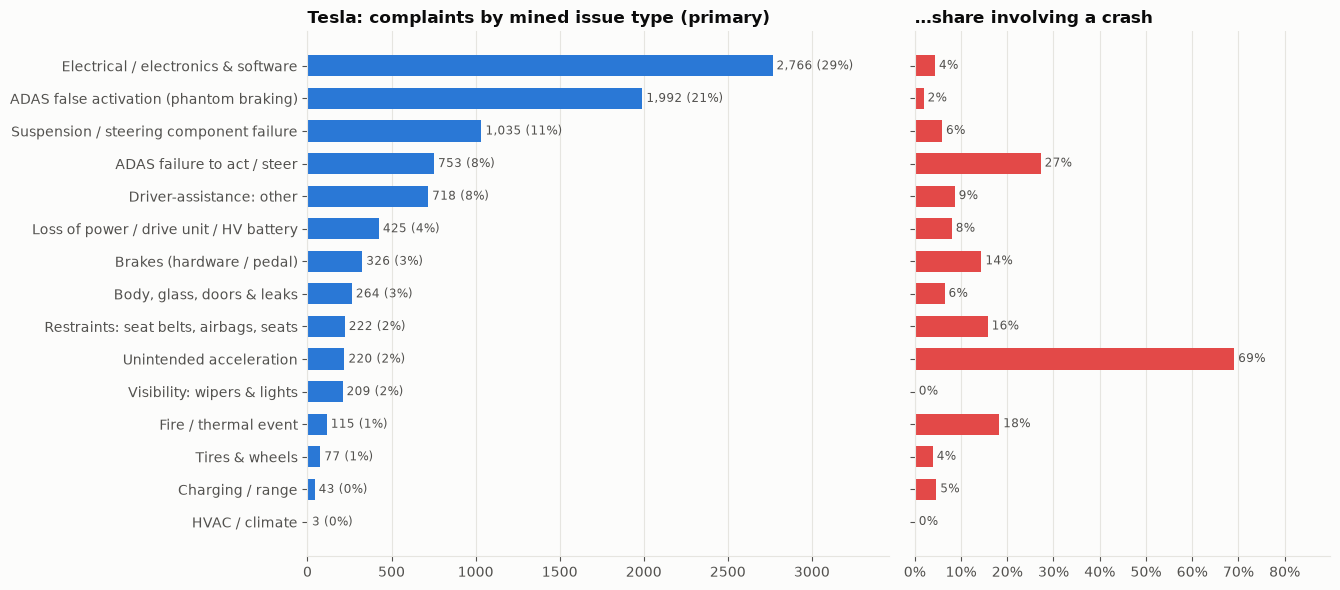

In [17]:
# Figure 4 – issue types: volume and severity
iss = issue_summary.drop("Unclassified", errors="ignore").iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6), sharey=True, gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].barh(iss.index, iss["complaints"], color=BLUE, height=0.65)
for y, (v, s) in enumerate(zip(iss["complaints"], iss["share"])): axes[0].text(v, y, f" {v:,} ({s:.0%})", va="center", fontsize=8.5, color=INK2)
axes[0].set_xlim(0, iss["complaints"].max() * 1.25); axes[0].grid(axis="y", visible=False)
axes[0].set_title(f"{FOCUS_MFR}: complaints by mined issue type (primary)")
axes[1].barh(iss.index, iss["crash_rate"], color=RED, height=0.65)
for y, v in enumerate(iss["crash_rate"]): axes[1].text(v, y, f" {v:.0%}", va="center", fontsize=8.5, color=INK2)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_xlim(0, iss["crash_rate"].max() * 1.3)
axes[1].set_title("…share involving a crash"); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_issue_types.png", dpi=160, bbox_inches="tight"); plt.show()

## 4. Patterns, trends and significant changes

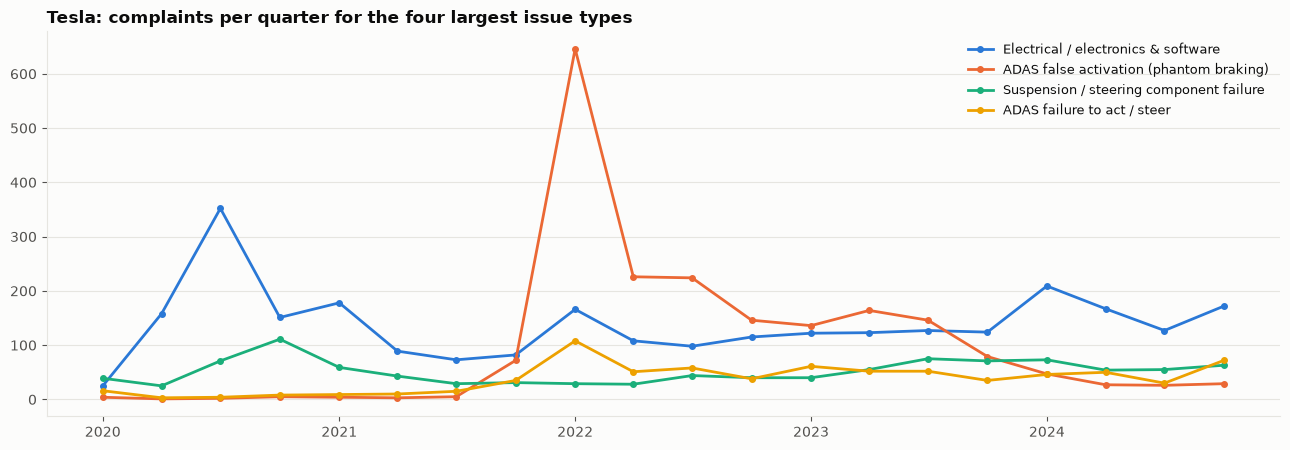

Most occurring failure (primary issue): Electrical / electronics & software - 2,766 complaints (29%)


,issue,year,previous year,this year,change
4,ADAS false activation (phantom braking),2022,84,1242,+1379%
8,Brakes (hardware / pedal),2022,12,152,+1167%
3,ADAS false activation (phantom braking),2021,12,84,+600%
11,Driver-assistance: other,2022,48,302,+529%
1,ADAS failure to act / steer,2022,69,255,+270%
0,ADAS failure to act / steer,2021,31,69,+123%
22,Unclassified,2023,62,130,+110%
19,"Restraints: seat belts, airbags, seats",2023,34,69,+103%
24,Unintended acceleration,2023,30,60,+100%
7,"Body, glass, doors & leaks",2023,41,72,+76%


,issue,month,complaints,monthly mean,z-score
0,Electrical / electronics & software,2020-06,155,46.1,3.2
1,Electrical / electronics & software,2020-07,208,46.1,4.8
2,ADAS false activation (phantom braking),2022-02,500,33.2,6.8
3,Suspension / steering component failure,2020-11,52,17.2,3.8
4,Suspension / steering component failure,2023-08,46,17.2,3.2
5,ADAS failure to act / steer,2022-02,84,12.6,5.7


In [18]:
# Quarterly volume by issue type + significant changes (year-over-year and month-level spikes)
corpus["quarter"] = corpus["LDATE"].dt.to_period("Q").dt.to_timestamp()
top4 = issue_summary.drop("Unclassified", errors="ignore").index[:4]
q = corpus[corpus["primary_issue"].isin(top4)].pivot_table(index="quarter", columns="primary_issue", values="ODINO", aggfunc="count").fillna(0)[top4]

fig, ax = plt.subplots(figsize=(13, 4.6))
for i, c in enumerate(top4):
    ax.plot(q.index, q[c], color=CAT[i], lw=2, marker="o", markersize=4, label=c)
ax.set_title(f"{FOCUS_MFR}: complaints per quarter for the four largest issue types"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_issue_trends.png", dpi=160, bbox_inches="tight"); plt.show()

yearly = corpus.pivot_table(index=corpus["LDATE"].dt.year, columns="primary_issue", values="ODINO", aggfunc="count").fillna(0)
yoy = yearly.pct_change().replace([np.inf, -np.inf], np.nan)
changes = []
for issue in yearly.columns:
    for yr in yearly.index[1:]:
        prev, cur = yearly.loc[yr - 1, issue], yearly.loc[yr, issue]
        if max(prev, cur) >= 40 and abs(cur - prev) >= 30:
            changes.append({"issue": issue, "year": yr, "previous year": int(prev), "this year": int(cur), "change": (cur - prev) / max(prev, 1)})
changes = pd.DataFrame(changes).sort_values("change", key=abs, ascending=False)

# month-level spikes: months > mean + 3 sd of the issue's own monthly series
mon = corpus.pivot_table(index="recv_month", columns="primary_issue", values="ODINO", aggfunc="count").fillna(0)
spikes = []
for issue in top4:
    s = mon[issue]; z = (s - s.mean()) / s.std()
    for m_, v in s[z > 3].items():
        spikes.append({"issue": issue, "month": m_.strftime("%Y-%m"), "complaints": int(v), "monthly mean": round(s.mean(), 1), "z-score": round(z[m_], 1)})
spikes = pd.DataFrame(spikes)
print("Most occurring failure (primary issue):", issue_summary.index[0], f"- {issue_summary['complaints'].iloc[0]:,} complaints ({issue_summary['share'].iloc[0]:.0%})")
display(changes.head(10).style.format({"change": "{:+.0%}"}))
spikes

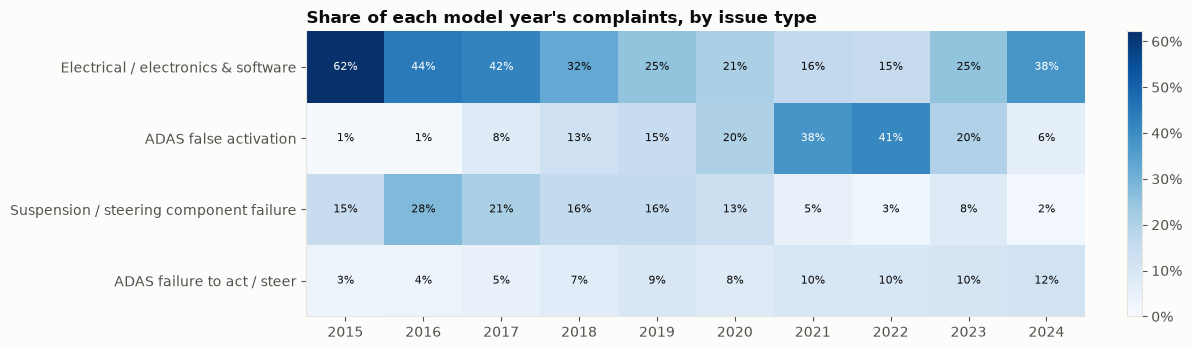

In [19]:
# Model-year cohort view for the top issues (share of each model year's complaints)
cohort = (corpus[corpus["YEARTXT"].between(2015, 2024)].pivot_table(index="YEARTXT", columns="primary_issue", values="ODINO", aggfunc="count")
          .fillna(0))
cohort_share = cohort.div(cohort.sum(axis=1), axis=0)[top4]
cohort_share.index = cohort_share.index.astype(int)
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(cohort_share.T.values, aspect="auto", cmap="Blues", vmin=0)
ax.set_xticks(range(len(cohort_share.index)), cohort_share.index); ax.set_yticks(range(len(top4)), [t.split(" (")[0] for t in top4])
for i in range(len(top4)):
    for j in range(len(cohort_share.index)):
        v = cohort_share.T.values[i, j]; ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.35 else INK)
ax.grid(False); ax.set_title("Share of each model year's complaints, by issue type"); plt.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0), fraction=0.02)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6_model_year_cohort.png", dpi=160, bbox_inches="tight"); plt.show()

## 5. Export — tagged complaints (Excel + CSV)

In [20]:
from openpyxl.styles import PatternFill, Font, Alignment
from openpyxl.utils import get_column_letter

j = lambda l: "; ".join(l) if isinstance(l, list) else l
out = pd.DataFrame({
    "ODI Number": corpus["ODINO"], "Date Received": corpus["LDATE"].dt.strftime("%Y-%m-%d"),
    "Failure Date": corpus["FAILDATE"].dt.strftime("%Y-%m-%d"), "Model": corpus["MODELTXT"], "Model Year": corpus["YEARTXT"].astype("Int64"),
    "NHTSA Component(s)": corpus["nhtsa_components"], "Complaint Text": corpus["text"],
    "Tags: Component": corpus["COMPONENT"].map(j), "Tags: Failure Mode": corpus["FAILURE_MODE"].map(j),
    "Tags: ADAS Feature": corpus["ADAS_FEATURE"].map(j), "Tags: Trigger / Condition": corpus["TRIGGER_CONDITION"].map(j),
    "Tags: Consequence": corpus["CONSEQUENCE"].map(j), "Tags: Service Action": corpus["SERVICE_ACTION"].map(j),
    "Key Phrases (TF-IDF)": corpus["key_phrases"].map(j),
    "Speed mph (structured or text)": corpus["speed_mph"], "Mileage": corpus["MILES"].fillna(corpus["mileage_text"]),
    "Repair Cost USD (text)": corpus["cost_usd_text"],
    "Issue Types (all)": corpus["issue_types"].map(j), "Primary Issue": corpus["primary_issue"], "Issue Group": corpus["issue_group"],
    "Embedding Cluster": corpus["cluster"], "Cluster Terms": corpus["cluster"].map(cluster_terms), "NMF Topic": corpus["nmf_topic"],
    "Crash": corpus["CRASH"], "Fire": corpus["FIRE"], "Injured": corpus["INJURED"], "Deaths": corpus["DEATHS"],
    "Towed": corpus["VEHICLES_TOWED_YN"], "State": corpus["STATE"],
}).sort_values("Date Received", ascending=False)
out.to_csv(OUT_DIR / f"{FOCUS_MFR.lower()}_complaints_tagged.csv", index=False, encoding="utf-8-sig")

xlsx = OUT_DIR / f"{FOCUS_MFR.lower()}_complaints_text_mining.xlsx"
with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    out.to_excel(xw, sheet_name="Complaints_Tagged", index=False)
    tag_freq.to_excel(xw, sheet_name="Tag_Frequency", index=False)
    pd.DataFrame([(c, t, p) for c, d in ENTITY_PATTERNS.items() for t, p in d.items()],
                 columns=["Entity Class", "Tag", "Pattern (regex)"]).to_excel(xw, sheet_name="Entity_Dictionary", index=False)
    issue_summary.reset_index().to_excel(xw, sheet_name="Issue_Summary", index=False)
    root_causes.reset_index().to_excel(xw, sheet_name="Root_Cause_Profiles", index=False)
    clusters.reset_index().to_excel(xw, sheet_name="Clusters", index=False)
    nmf_topics.to_excel(xw, sheet_name="NMF_Topics", index=False)
    changes.to_excel(xw, sheet_name="Significant_Changes", index=False)
    (spikes if len(spikes) else pd.DataFrame({"note": ["no month above mean + 3 sd"]})).to_excel(xw, sheet_name="Monthly_Spikes", index=False)
    comp.reset_index().head(40).to_excel(xw, sheet_name="EDA_Components_AllMakes", index=False)
    profile.to_excel(xw, sheet_name="EDA_Column_Profile", index=False)
    dq_log.to_excel(xw, sheet_name="EDA_Data_Quality_Log", index=False)

    hdr_fill, hdr_font = PatternFill("solid", fgColor="1F3A5F"), Font(color="FFFFFF", bold=True)
    tag_fill = PatternFill("solid", fgColor="E3EEFB"); iss_fill = PatternFill("solid", fgColor="FFF4D6")
    for ws in xw.book.worksheets:
        for c in ws[1]: c.fill, c.font, c.alignment = hdr_fill, hdr_font, Alignment(wrap_text=True, vertical="center")
        ws.freeze_panes = "B2"; ws.auto_filter.ref = ws.dimensions
        for i, col in enumerate(ws.iter_cols(min_row=1, max_row=min(ws.max_row, 50)), 1):
            ws.column_dimensions[get_column_letter(i)].width = min(max(10, max(len(str(c.value or "")) for c in col) * 0.9), 55)
    ws = xw.book["Complaints_Tagged"]
    ws.column_dimensions["G"].width = 90
    hdrs = [c.value for c in ws[1]]
    for row in ws.iter_rows(min_row=2, max_row=ws.max_row):
        for c in row:
            h = hdrs[c.column - 1]
            if h.startswith("Tags:") or h.startswith("Key Phrases"): c.fill = tag_fill
            elif h in ("Primary Issue", "Issue Group", "Issue Types (all)"): c.fill = iss_fill
            c.alignment = Alignment(wrap_text=(h == "Complaint Text"), vertical="top")
print(f"Saved {xlsx.name} ({len(out):,} tagged complaints) and the CSV.")
for name, obj in [("issue_summary", issue_summary), ("root_causes", root_causes), ("clusters", clusters), ("changes", changes),
                  ("eda_components", comp.head(40)), ("tag_freq", tag_freq), ("dq_log", dq_log)]:
    obj.to_csv(OUT_DIR / f"{name}.csv")
pd.Series({"rows_raw": len(raw), "complaints_all": cmp["ODINO"].nunique(), "focus_complaints": len(corpus), "k": K,
           "ami": adjusted_mutual_info_score(corpus['cluster'], corpus['nmf_topic']),
           "classified_share": (corpus['primary_issue'] != 'Unclassified').mean(),
           "unknown_component_share": unk.mean(), "unknown_recovered": (corpus.loc[unk, 'primary_issue'] != 'Unclassified').mean(),
           "crash_all": cmp["CRASH"].mean(), "crash_focus": corpus["CRASH"].mean(),
           "median_age_all": cmp["vehicle_age_yrs"].median(), "early_life_share": (cmp['vehicle_age_yrs'].dropna() <= 2).mean(),
           "upper_case_share": (corpus['text'] == corpus['text'].str.upper()).mean()}).to_csv(OUT_DIR / "headline_metrics.csv")

Saved tesla_complaints_text_mining.xlsx (9,544 tagged complaints) and the CSV.


## 6. Summary (see `Task2_Report.docx` for the stakeholder version)
* **Data:** 418k complaint × component rows (about 292k unique complaints) from 2020–2024. Missing data is concentrated in fields that only
  apply to some products (tires, child seats). Zeros, `9999` and `UNKNOWN OR OTHER` are sentinel codes and are converted to missing values.
* **Text mining:** the narrative is the only place symptoms, triggers and context are recorded. A seven-class entity schema plus TF-IDF key
  phrases turns it into structured tags, and 15 rule-based issue types group them. Text mining also classifies most complaints that NHTSA filed
  as `UNKNOWN OR OTHER`.
* **Clustering:** embedding clusters and NMF topics independently recover the same main failure families. Root-cause profiling (condition lift,
  mileage, model year) turns them into testable engineering hypotheses.